# 🖼️ ConvNeXt Transfer Learning - CIFAR-100 Classification (100 Classes)
Mô hình **ConvNeXt-Tiny** pretrained trên ImageNet + bộ dữ liệu **CIFAR-100** của tác giả **fedesoriano** trên Kaggle.
- **100 lớp đối tượng** (60.000 ảnh kích thước gốc 32x32: 50.000 train, 10.000 test).
- Sử dụng **`transforms.Resize((224, 224))`** để upscale ảnh lên kích thước chuẩn của ConvNeXt.
- Áp dụng cơ chế **Save Best & Load Best Model** ở cả 2 giai đoạn (Train Head & Fine-Tuning Toàn Bộ).
- **Biểu đồ theo dõi Loss & Accuracy** qua các Epochs (Train vs Val).
- Trực quan hóa 1st Conv Filters, Feature Vector t-SNE 2D, Confusion Matrix và Classification Report.

## 1. Khởi tạo thư viện & Thiết bị (Device)

In [1]:
import os
import copy
import pickle
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms.v2 as transforms
import torchvision.models as models
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 2. Tải Mô hình ConvNeXt Pretrained (ImageNet)

In [2]:
# Tải mô hình ConvNeXt-Tiny kèm bộ trọng số ImageNet-1K chính thức (weights=DEFAULT)
weights = models.ConvNeXt_Tiny_Weights.DEFAULT
convnext_model = models.convnext_tiny(weights=weights)
print("Pretrained ConvNeXt-Tiny loaded successfully!")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 227MB/s]  


Pretrained ConvNeXt-Tiny loaded successfully!


In [3]:
print(convnext_model)

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

## 3. Freeze Base Model (Đóng băng đặc trưng đã học từ ImageNet)

In [4]:
# Đóng băng toàn bộ phần backbone features
convnext_model.requires_grad_(False)
print("Base model frozen:", not next(iter(convnext_model.features.parameters())).requires_grad)

Base model frozen: True


## 4. Thay thế lớp Classifier (Cắt lớp 1000 neuron ImageNet thay bằng 100 lớp CIFAR-100)


In [5]:
# Bộ dữ liệu CIFAR-100 gồm 100 lớp
N_CLASSES = 100

# Trong ConvNeXt, classifier[2] là Linear(768, 1000)
# Ta thay bằng Linear(768, N_CLASSES)
convnext_model.classifier[2] = nn.Linear(768, N_CLASSES)
convnext_model = convnext_model.to(device)
print(convnext_model.classifier)


Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=100, bias=True)
)


In [6]:
print(convnext_model)

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

## 5. Cấu hình Loss, Optimizer & Data Transforms (Kèm transforms.Resize 224x224)


In [7]:
# Loss function với Label Smoothing nhẹ để chống overfitting trên 100 lớp
loss_function = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = Adam(convnext_model.classifier[2].parameters(), lr=1e-3)

pre_trans = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_trans = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop((224, 224), scale=(0.75, 1.0), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2)
])


## 6. Nạp Dữ liệu CIFAR-100 (fedesoriano/cifar100) & Khởi tạo DataLoader


In [8]:
# --- CELL 6: NẠP DỮ LIỆU CIFAR-100 ---
# Danh sách chuẩn 100 lớp của CIFAR-100
CIFAR100_CLASSES = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 
    'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 
    'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 
    'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 
    'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 
    'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 
    'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 
    'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 
    'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 
    'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 
    'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 
    'television', 'tiger', 'tractor', 'train', 'trout', 'tulip', 'turtle', 
    'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]

class CIFAR100PickleDataset(Dataset):
    """Dataset nạp trực tiếp file pickle train/test từ fedesoriano/cifar100 trên Kaggle"""
    def __init__(self, file_path, transform=None):
        self.transform = transform
        with open(file_path, 'rb') as f:
            entry = pickle.load(f, encoding='latin1')
        
        # Reshape (N, 3072) -> (N, 3, 32, 32) -> (N, 32, 32, 3) RGB uint8
        raw_data = entry['data']
        self.data = raw_data.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        # Lấy nhãn 100 lớp (fine_labels)
        self.targets = entry.get('fine_labels', entry.get('labels', []))
        self.classes = CIFAR100_CLASSES

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_arr = self.data[idx]
        img = Image.fromarray(img_arr)
        target = self.targets[idx]
        if self.transform:
            img = self.transform(img)
        return img, target

# Đường dẫn cố định theo bộ dữ liệu của bạn trên Kaggle
DATA_DIR = "/kaggle/input/datasets/fedesoriano/cifar100"
TRAIN_FILE = os.path.join(DATA_DIR, "train")
TEST_FILE = os.path.join(DATA_DIR, "test")

print(f" Sử dụng đường dẫn dataset: {DATA_DIR}")
train_data = CIFAR100PickleDataset(TRAIN_FILE, transform=pre_trans)
valid_data = CIFAR100PickleDataset(TEST_FILE, transform=pre_trans)

# Khởi tạo DataLoader
batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print('\n NẠP DỮ LIỆU HOÀN TẤT:')
print(f'• Số ảnh Train: {len(train_data):,} ảnh')
print(f'• Số ảnh Valid (Test): {len(valid_data):,} ảnh')
print(f'• Tổng số lớp: {len(CIFAR100_CLASSES)} lớp')


 Sử dụng đường dẫn dataset: /kaggle/input/datasets/fedesoriano/cifar100

 NẠP DỮ LIỆU HOÀN TẤT:
• Số ảnh Train: 50,000 ảnh
• Số ảnh Valid (Test): 10,000 ảnh
• Tổng số lớp: 100 lớp


## 7a. Huấn luyện Giai đoạn 1: Train Classifier Head (Save Best Model)

In [9]:
def train_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss, correct = 0, 0
    for x, y in loader:
        x, y = train_trans(x).to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

def validate_epoch(model, loader, loss_fn):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

# Khởi tạo cấu trúc lưu lịch sử huấn luyện
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

best_val_acc = 0.0
best_weights = copy.deepcopy(convnext_model.state_dict())

epochs_head = 8
for epoch in range(1, epochs_head + 1):
    tr_loss, tr_acc = train_epoch(convnext_model, train_loader, optimizer, loss_function)
    val_loss, val_acc = validate_epoch(convnext_model, valid_loader, loss_function)
    
    # Ghi nhận vào lịch sử
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(val_acc)
    
    status = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(convnext_model.state_dict())
        torch.save(best_weights, "convnext_cifar100_head_best.pth")
        
    print(f"Epoch {epoch:02d}/{epochs_head:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} {status}")

# NẠP LẠI TRỌNG SỐ TỐT NHẤT CỦA GIAI ĐOẠN 1
convnext_model.load_state_dict(best_weights)


Epoch 01/08 | Train Loss: 2.9256 Acc: 0.4056 | Val Loss: 2.0826 Acc: 0.6335 
Epoch 02/08 | Train Loss: 2.4864 Acc: 0.5076 | Val Loss: 2.0997 Acc: 0.6520 
Epoch 03/08 | Train Loss: 2.3965 Acc: 0.5355 | Val Loss: 2.1382 Acc: 0.6599 
Epoch 04/08 | Train Loss: 2.3396 Acc: 0.5528 | Val Loss: 2.1365 Acc: 0.6646 
Epoch 05/08 | Train Loss: 2.3015 Acc: 0.5639 | Val Loss: 2.1754 Acc: 0.6609 
Epoch 06/08 | Train Loss: 2.2773 Acc: 0.5689 | Val Loss: 2.1908 Acc: 0.6626 
Epoch 07/08 | Train Loss: 2.2604 Acc: 0.5745 | Val Loss: 2.2194 Acc: 0.6612 
Epoch 08/08 | Train Loss: 2.2376 Acc: 0.5831 | Val Loss: 2.2412 Acc: 0.6589 


<All keys matched successfully>

## 7b. Huấn luyện Giai đoạn 2: Fine-Tuning Toàn Bộ Mô Hình (Save Best Model)

In [10]:
# Mở khóa toàn bộ mô hình (Unfreeze base model)
convnext_model.requires_grad_(True)

# Optimizer với learning rate nhỏ để fine-tune
optimizer_ft = Adam(convnext_model.parameters(), lr=1e-5)

epochs_ft = 10
for epoch in range(1, epochs_ft + 1):
    tr_loss, tr_acc = train_epoch(convnext_model, train_loader, optimizer_ft, loss_function)
    val_loss, val_acc = validate_epoch(convnext_model, valid_loader, loss_function)
    
    # Ghi nhận tiếp vào lịch sử
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(val_acc)
    
    status = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(convnext_model.state_dict())
        torch.save(best_weights, "convnext_cifar100_best.pth")
        
    print(f"Fine-tune Epoch {epoch:02d}/{epochs_ft:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} {status}")

# Nạp lại bản ghi tốt nhất tuyệt đối
convnext_model.load_state_dict(best_weights)


Fine-tune Epoch 01/10 | Train Loss: 1.9066 Acc: 0.6653 | Val Loss: 1.7755 Acc: 0.7138 
Fine-tune Epoch 02/10 | Train Loss: 1.7038 Acc: 0.7264 | Val Loss: 1.6594 Acc: 0.7452 
Fine-tune Epoch 03/10 | Train Loss: 1.6021 Acc: 0.7555 | Val Loss: 1.6250 Acc: 0.7505 
Fine-tune Epoch 04/10 | Train Loss: 1.5185 Acc: 0.7832 | Val Loss: 1.5489 Acc: 0.7742 
Fine-tune Epoch 05/10 | Train Loss: 1.4514 Acc: 0.8042 | Val Loss: 1.5189 Acc: 0.7827 
Fine-tune Epoch 06/10 | Train Loss: 1.3882 Acc: 0.8257 | Val Loss: 1.4727 Acc: 0.7969 
Fine-tune Epoch 07/10 | Train Loss: 1.3371 Acc: 0.8425 | Val Loss: 1.4567 Acc: 0.7998 
Fine-tune Epoch 08/10 | Train Loss: 1.2918 Acc: 0.8577 | Val Loss: 1.4557 Acc: 0.8006 
Fine-tune Epoch 09/10 | Train Loss: 1.2529 Acc: 0.8716 | Val Loss: 1.4420 Acc: 0.8011 
Fine-tune Epoch 10/10 | Train Loss: 1.2159 Acc: 0.8859 | Val Loss: 1.4219 Acc: 0.8119 


<All keys matched successfully>

## 7c. Vẽ Biểu đồ Theo dõi Loss & Accuracy qua các Epochs (Train vs Val)

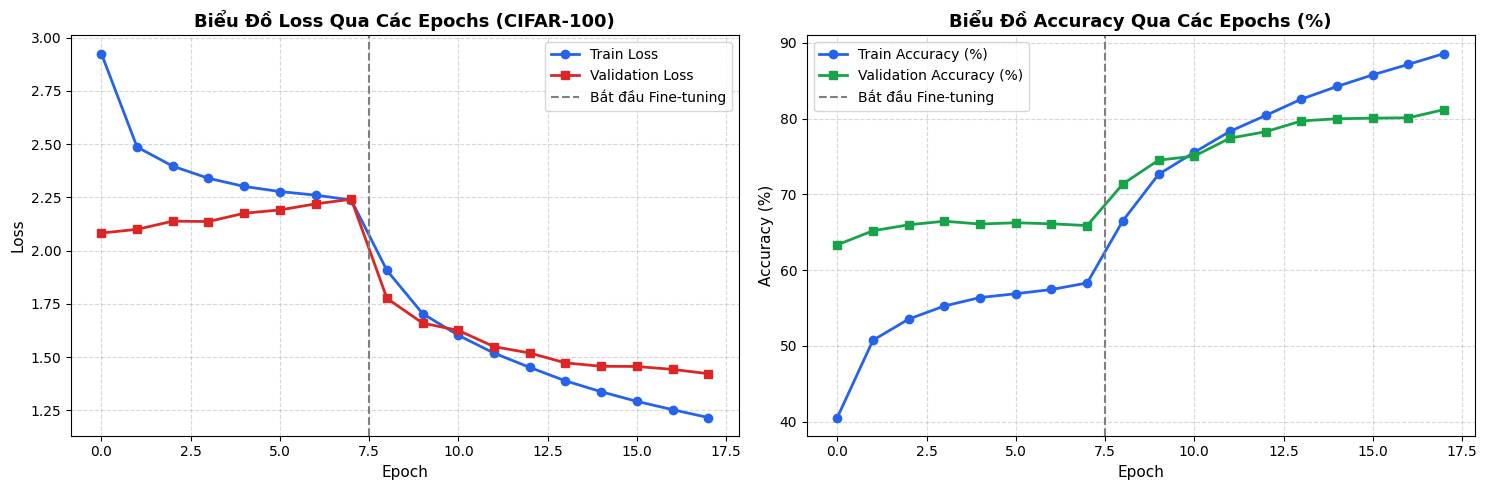

 Đã lưu biểu đồ Loss & Accuracy vào file 'training_history_curves_cifar100.png'


In [11]:
# Vẽ 2 đồ thị song song: Đường cong Loss và Đường cong Accuracy qua các Epochs
plt.figure(figsize=(15, 5))

# 1. Đồ thị Loss
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', color='#2563eb', linewidth=2, marker='o')
plt.plot(history['val_loss'], label='Validation Loss', color='#dc2626', linewidth=2, marker='s')
plt.axvline(x=epochs_head - 0.5, color='gray', linestyle='--', label='Bắt đầu Fine-tuning')
plt.title('Biểu Đồ Loss Qua Các Epochs (CIFAR-100)', fontsize=13, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# 2. Đồ thị Accuracy (%)
plt.subplot(1, 2, 2)
plt.plot([acc * 100 for acc in history['train_acc']], label='Train Accuracy (%)', color='#2563eb', linewidth=2, marker='o')
plt.plot([acc * 100 for acc in history['val_acc']], label='Validation Accuracy (%)', color='#16a34a', linewidth=2, marker='s')
plt.axvline(x=epochs_head - 0.5, color='gray', linestyle='--', label='Bắt đầu Fine-tuning')
plt.title('Biểu Đồ Accuracy Qua Các Epochs (%)', fontsize=13, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy (%)', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('training_history_curves_cifar100.png', dpi=300)
plt.show()
print(" Đã lưu biểu đồ Loss & Accuracy vào file 'training_history_curves_cifar100.png'")


## 8. Visualize 1st Conv Filters 

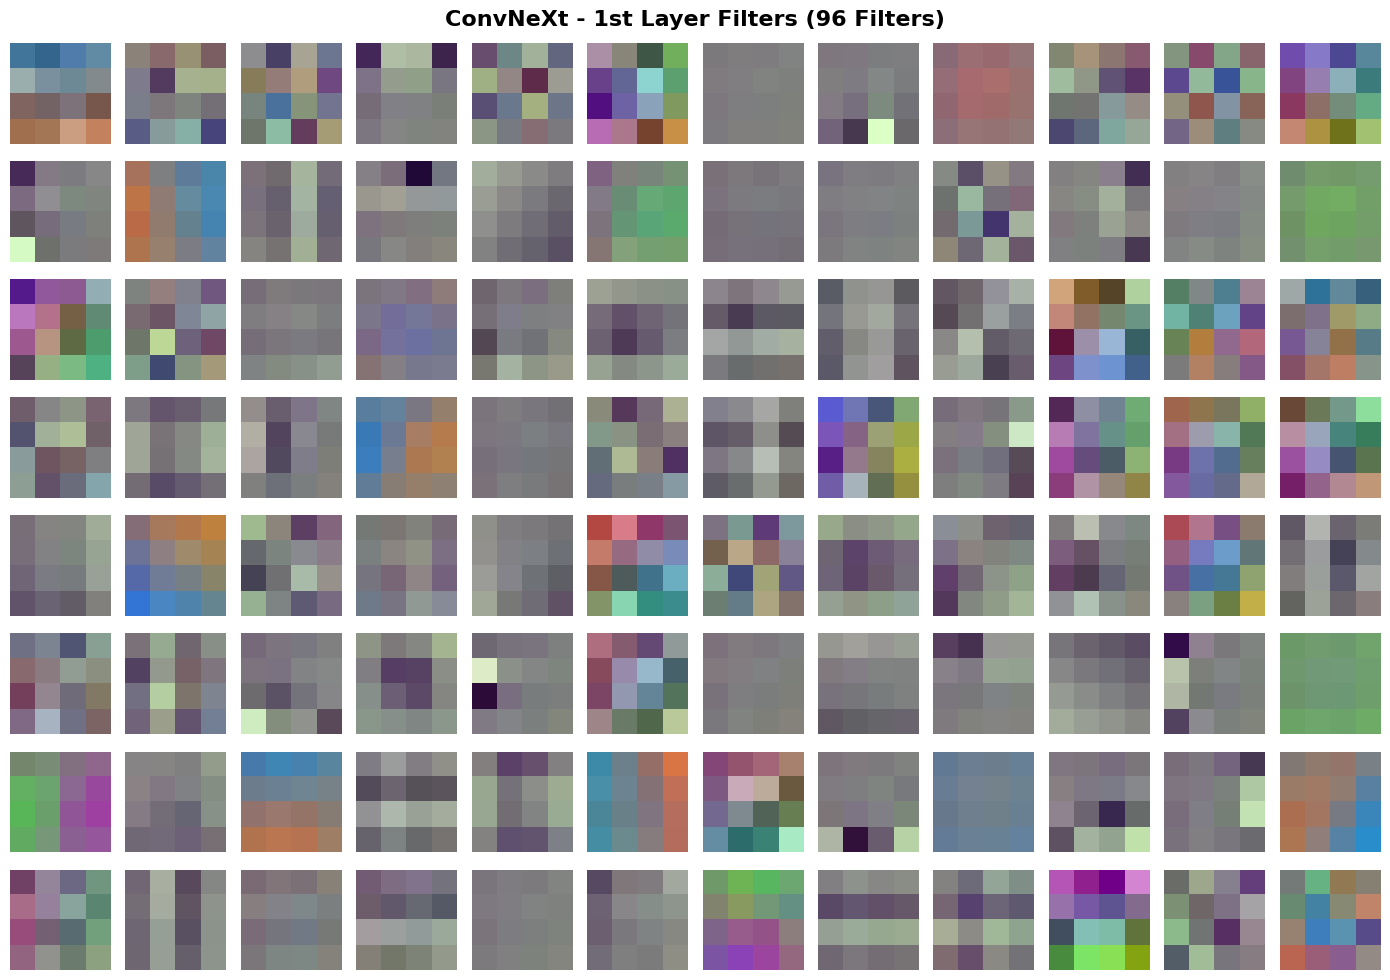

Đã lưu hình vào 'viz_1st_conv_filters.png'!


In [12]:
# Lấy trọng số của 96 filters tầng Conv đầu tiên (features[0][0])
weights_conv1 = convnext_model.features[0][0].weight.data.cpu()  # shape: (96, 3, 4, 4)

# Chuẩn hóa về [0, 1] để vẽ ảnh màu
w_min, w_max = weights_conv1.min(), weights_conv1.max()
weights_norm = (weights_conv1 - w_min) / (w_max - w_min)

fig, axes = plt.subplots(8, 12, figsize=(14, 10))
for i, ax in enumerate(axes.flat):
    if i < len(weights_norm):
        # Transpose từ (C, H, W) sang (H, W, C) để matplotlib vẽ RGB
        ax.imshow(weights_norm[i].permute(1, 2, 0).numpy())
    ax.axis('off')
plt.suptitle("ConvNeXt - 1st Layer Filters (96 Filters)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("viz_1st_conv_filters.png", dpi=300)
plt.show()
print("Đã lưu hình vào 'viz_1st_conv_filters.png'!")

## 9. Trích xuất Feature Vector (768 chiều) & Giảm chiều t-SNE 2D


Đang tính toán phân bố cụm t-SNE trên 2528 mẫu...


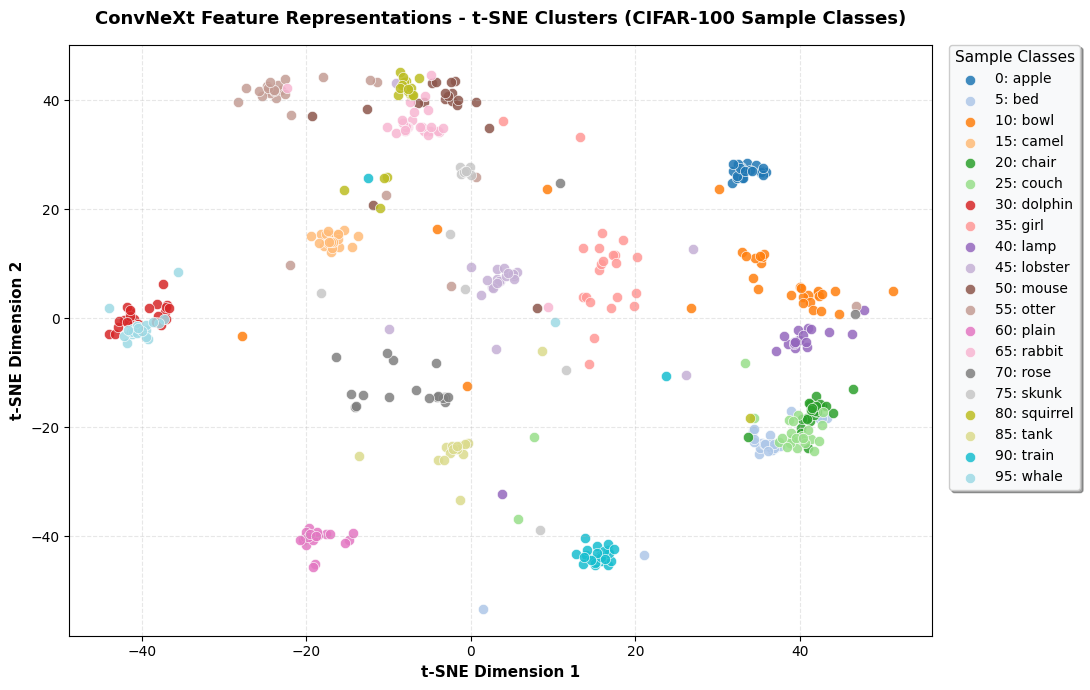

 Đã lưu biểu đồ cụm t-SNE vào 'viz_tsne_clusters_cifar100.png


In [13]:
# --- CELL 9: TRÍCH XUẤT 768D FEATURE VECTOR & VẼ CỤM t-SNE 2D ---

# 1. Trích xuất feature vector 768 chiều trước lớp Linear cuối (trên tập Valid/Test)
features_list = []
labels_list = []

convnext_model.eval()
with torch.no_grad():
    # Lấy mẫu một phần tập valid để tính t-SNE nhanh và chính xác (tối đa ~2500 mẫu)
    sample_count = 0
    for x, y in valid_loader:
        x = x.to(device)
        feat = convnext_model.features(x)
        feat = convnext_model.avgpool(feat)
        feat = convnext_model.classifier[0](feat)  # LayerNorm
        feat = convnext_model.classifier[1](feat)  # Flatten -> (batch, 768)
        features_list.append(feat.cpu().numpy())
        labels_list.append(y.numpy())
        sample_count += len(y)
        if sample_count >= 2500:
            break

X_features = np.concatenate(features_list, axis=0)
y_labels = np.concatenate(labels_list, axis=0)

# 2. Giảm chiều từ 768D xuống 2D bằng t-SNE
print(f"Đang tính toán phân bố cụm t-SNE trên {len(X_features)} mẫu...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d = tsne.fit_transform(X_features)

# 3. Chọn 10 lớp đại diện trải đều để vẽ biểu đồ và legend rõ ràng, đẹp mắt
selected_class_indices = list(range(0, 100, 5))
selected_names = [CIFAR100_CLASSES[i] for i in selected_class_indices]
colors = plt.cm.tab20(np.linspace(0, 1, len(selected_class_indices)))

# 4. Vẽ biểu đồ phân bố cụm với Legend nằm gọn gàng bên phải
plt.figure(figsize=(11, 7))

for idx, cls_idx in enumerate(selected_class_indices):
    mask = (y_labels == cls_idx)
    if np.sum(mask) > 0:
        plt.scatter(
            X_2d[mask, 0], X_2d[mask, 1],
            color=colors[idx],
            label=f"{cls_idx}: {selected_names[idx]}",
            s=55,
            alpha=0.85,
            edgecolors='white',
            linewidth=0.5
        )

plt.title("ConvNeXt Feature Representations - t-SNE Clusters (CIFAR-100 Sample Classes)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("t-SNE Dimension 1", fontsize=11, fontweight='bold')
plt.ylabel("t-SNE Dimension 2", fontsize=11, fontweight='bold')
plt.grid(True, linestyle="--", alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    borderaxespad=0.,
    title="Sample Classes",
    title_fontsize=11,
    fontsize=10,
    frameon=True,
    facecolor='#f8f9fa',
    edgecolor='#ccc',
    shadow=True
)

plt.tight_layout()
plt.savefig("viz_tsne_clusters_cifar100.png", dpi=300, bbox_inches='tight')
plt.show()
print(" Đã lưu biểu đồ cụm t-SNE vào 'viz_tsne_clusters_cifar100.png")


## 10. Đánh giá Độ chính xác (%), Validation Loss & Ma trận nhầm lẫn (Confusion Matrix)


 FINAL VALIDATION LOSS     : 1.4219
 FINAL VALIDATION ACCURACY : 81.19%

 BÁO CÁO PHÂN LOẠI TỔNG QUAN (CLASSIFICATION REPORT):
               precision    recall  f1-score   support

        apple     0.9515    0.9800    0.9655       100
aquarium_fish     0.9451    0.8600    0.9005       100
         baby     0.7000    0.7700    0.7333       100
         bear     0.9589    0.7000    0.8092       100
       beaver     0.8101    0.6400    0.7151       100
          bed     0.8119    0.8200    0.8159       100
          bee     0.8947    0.8500    0.8718       100
       beetle     0.9136    0.7400    0.8177       100
      bicycle     0.8305    0.9800    0.8991       100
       bottle     0.9314    0.9500    0.9406       100
         bowl     0.7021    0.6600    0.6804       100
          boy     0.5435    0.5000    0.5208       100
       bridge     0.9062    0.8700    0.8878       100
          bus     0.9286    0.7800    0.8478       100
    butterfly     0.9398    0.7800    0.8525   

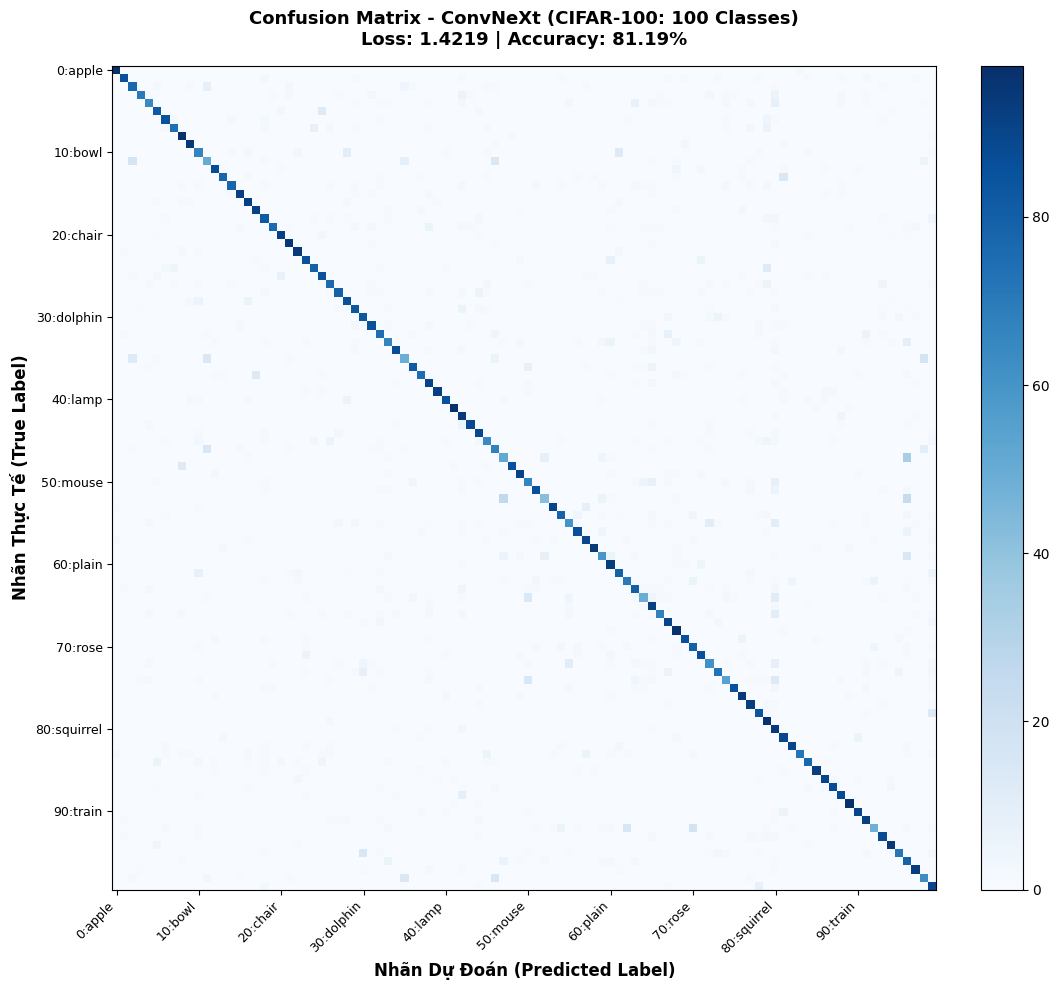

 Đã lưu ma trận nhầm lẫn vào file 'confusion_matrix_cifar100.png'!


In [14]:
# --- CELL 10: ĐÁNH GIÁ CHUẨN XÁC VÀ MA TRẬN NHẦM LẪN (CONFUSION MATRIX 100 LỚP) ---

# 1. Đánh giá toàn bộ tập Validation: Tính Loss và nhãn dự đoán
y_true_all, y_pred_all = [], []
total_val_loss = 0.0

convnext_model.eval()
with torch.no_grad():
    for x, y in valid_loader:
        x, y = x.to(device), y.to(device)
        out = convnext_model(x)
        
        loss = loss_function(out, y)
        total_val_loss += loss.item() * len(y)
        
        preds = out.argmax(dim=1).cpu().numpy()
        y_pred_all.extend(preds)
        y_true_all.extend(y.cpu().numpy())

val_loss = total_val_loss / len(valid_loader.dataset)
val_acc = accuracy_score(y_true_all, y_pred_all) * 100

print("=" * 65)
print(f" FINAL VALIDATION LOSS     : {val_loss:.4f}")
print(f" FINAL VALIDATION ACCURACY : {val_acc:.2f}%")
print("=" * 65)

labels_idx = list(range(len(CIFAR100_CLASSES)))

# Báo cáo Precision, Recall, F1-Score tổng quan trên 100 lớp
print("\n BÁO CÁO PHÂN LOẠI TỔNG QUAN (CLASSIFICATION REPORT):")
print(classification_report(y_true_all, y_pred_all, labels=labels_idx, target_names=CIFAR100_CLASSES, digits=4, zero_division=0))

# 2. Vẽ Ma trận nhầm lẫn (Confusion Matrix cho 100 lớp dạng Heatmap sắc nét)
cm = confusion_matrix(y_true_all, y_pred_all, labels=labels_idx)

plt.figure(figsize=(12, 10))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title(f"Confusion Matrix - ConvNeXt (CIFAR-100: 100 Classes)\nLoss: {val_loss:.4f} | Accuracy: {val_acc:.2f}%", 
          fontsize=13, fontweight='bold', pad=15)
plt.colorbar(fraction=0.046, pad=0.04)

# Vì có 100 lớp nên hiển thị tick mark cách nhau mỗi 10 lớp để biểu đồ thoáng đẹp
step_ticks = np.arange(0, 100, 10)
plt.xticks(step_ticks, [f"{i}:{CIFAR100_CLASSES[i]}" for i in step_ticks], rotation=45, ha='right', fontsize=9)
plt.yticks(step_ticks, [f"{i}:{CIFAR100_CLASSES[i]}" for i in step_ticks], fontsize=9)

plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=12, fontweight='bold')
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=12, fontweight='bold')
plt.tight_layout()

plt.savefig("confusion_matrix_cifar100.png", dpi=300)
plt.show()
print(" Đã lưu ma trận nhầm lẫn vào file 'confusion_matrix_cifar100.png'!")
